# Array interference suppression
The main question is whether posterior decisions improve beamforming enough to justify their additional cost. These figures distinguish **tracking**, **posterior averaging**, and **model mismatch**. They retain every scenario, including cases where a cheaper reference wins.

The original complex study has 16 channels, rank three, interference-only training, independent evaluation snapshots, and supplied motion equal to half the physical motion. Desired orientation, snapshot count, drift, unequal powers, source correlation, and desired-signal contamination are varied separately. Mean and modal beamformers share parameters and variances. The marginal Bingham mode equals matching EW PCA.

Every figure uses TeX, 200 dpi, and a larger canvas. Blue in a signed-gain map favors the posterior mean; red favors the reference. A confidence interval crossing zero does not establish an improvement. The eight-trajectory application experiment is a pilot; intervals are paired Student intervals, not simultaneous bands.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess
ROOT=Path.cwd() if (Path.cwd()/'lib').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from lib.validation import require_gate
print('Numerical core:',require_gate(ROOT)['status'])
from lib.plotting import plt
from lib.reporting import run_or_load
from lib.visuals import (array_overview,field_overview,paired_field,coverage_regions,
    cost_tradeoff,field_maps,calibration_overview,noise_overview,sampler_overview,predictive_scores)
from lib.decision_visuals import load_study,gain_maps,decision_calibration
import numpy as np
import pandas as pd
from IPython.display import display
OUT=ROOT/'results'
assert plt.rcParams['text.usetex'] and plt.rcParams['figure.dpi']==200
assert plt.rcParams['savefig.dpi']==200

def show(fig):
    assert fig.dpi==200
    plt.show()
    plt.close(fig)

# Unchanged raw application simulations are checksum-verified and reused.
config=dict(repeats=8,T=72,draws=6000,burnin=2500,max_draws=24000,max_burnin=8000)

result=run_or_load(ROOT,'case1',dict(seed=1729,workers=4,checkpoint_dir='results/checkpoints/array',**config))
m=result['metrics'];regions=result['regions']
display(result['config'])

Numerical core: passed


case1: loading verified simulation tables


{'seed': 1729,
 'repeats': 8,
 'T': 72,
 'draws': 6000,
 'burnin': 2500,
 'n': 16,
 'k': 3,
 's': 0.3,
 'tau2': 2.0,
 'checkpoints': [12, 36, 72],
 'max_draws': 24000,
 'max_burnin': 8000,
 'coverage_distribution': 'Repeated independent observations of deterministic moving subspace paths',
 'known_motion_fraction': 0.5,
 'validation_candidates': 3,
 'evaluation_snapshots': 256,
 'nominal_mass': 0.95,
 'coverage_guaranteed': False,
 'workers': 4,
 'checkpoint_dir': 'results/checkpoints/array'}

## Separate the two comparisons
The left map isolates posterior averaging by comparing the mean and mode from the **same posterior**. The right compares against validation-tuned loaded covariance. Gains versus loaded covariance can include structural assumptions and different estimators; they are not all attributable to posterior uncertainty.

Each cell gives the paired mean SINR gain and its 95% interval in dB. Color scales are separate so small mean–mode effects remain visible. The source tables preserve independent held-out power and lower-tail SINR as well.

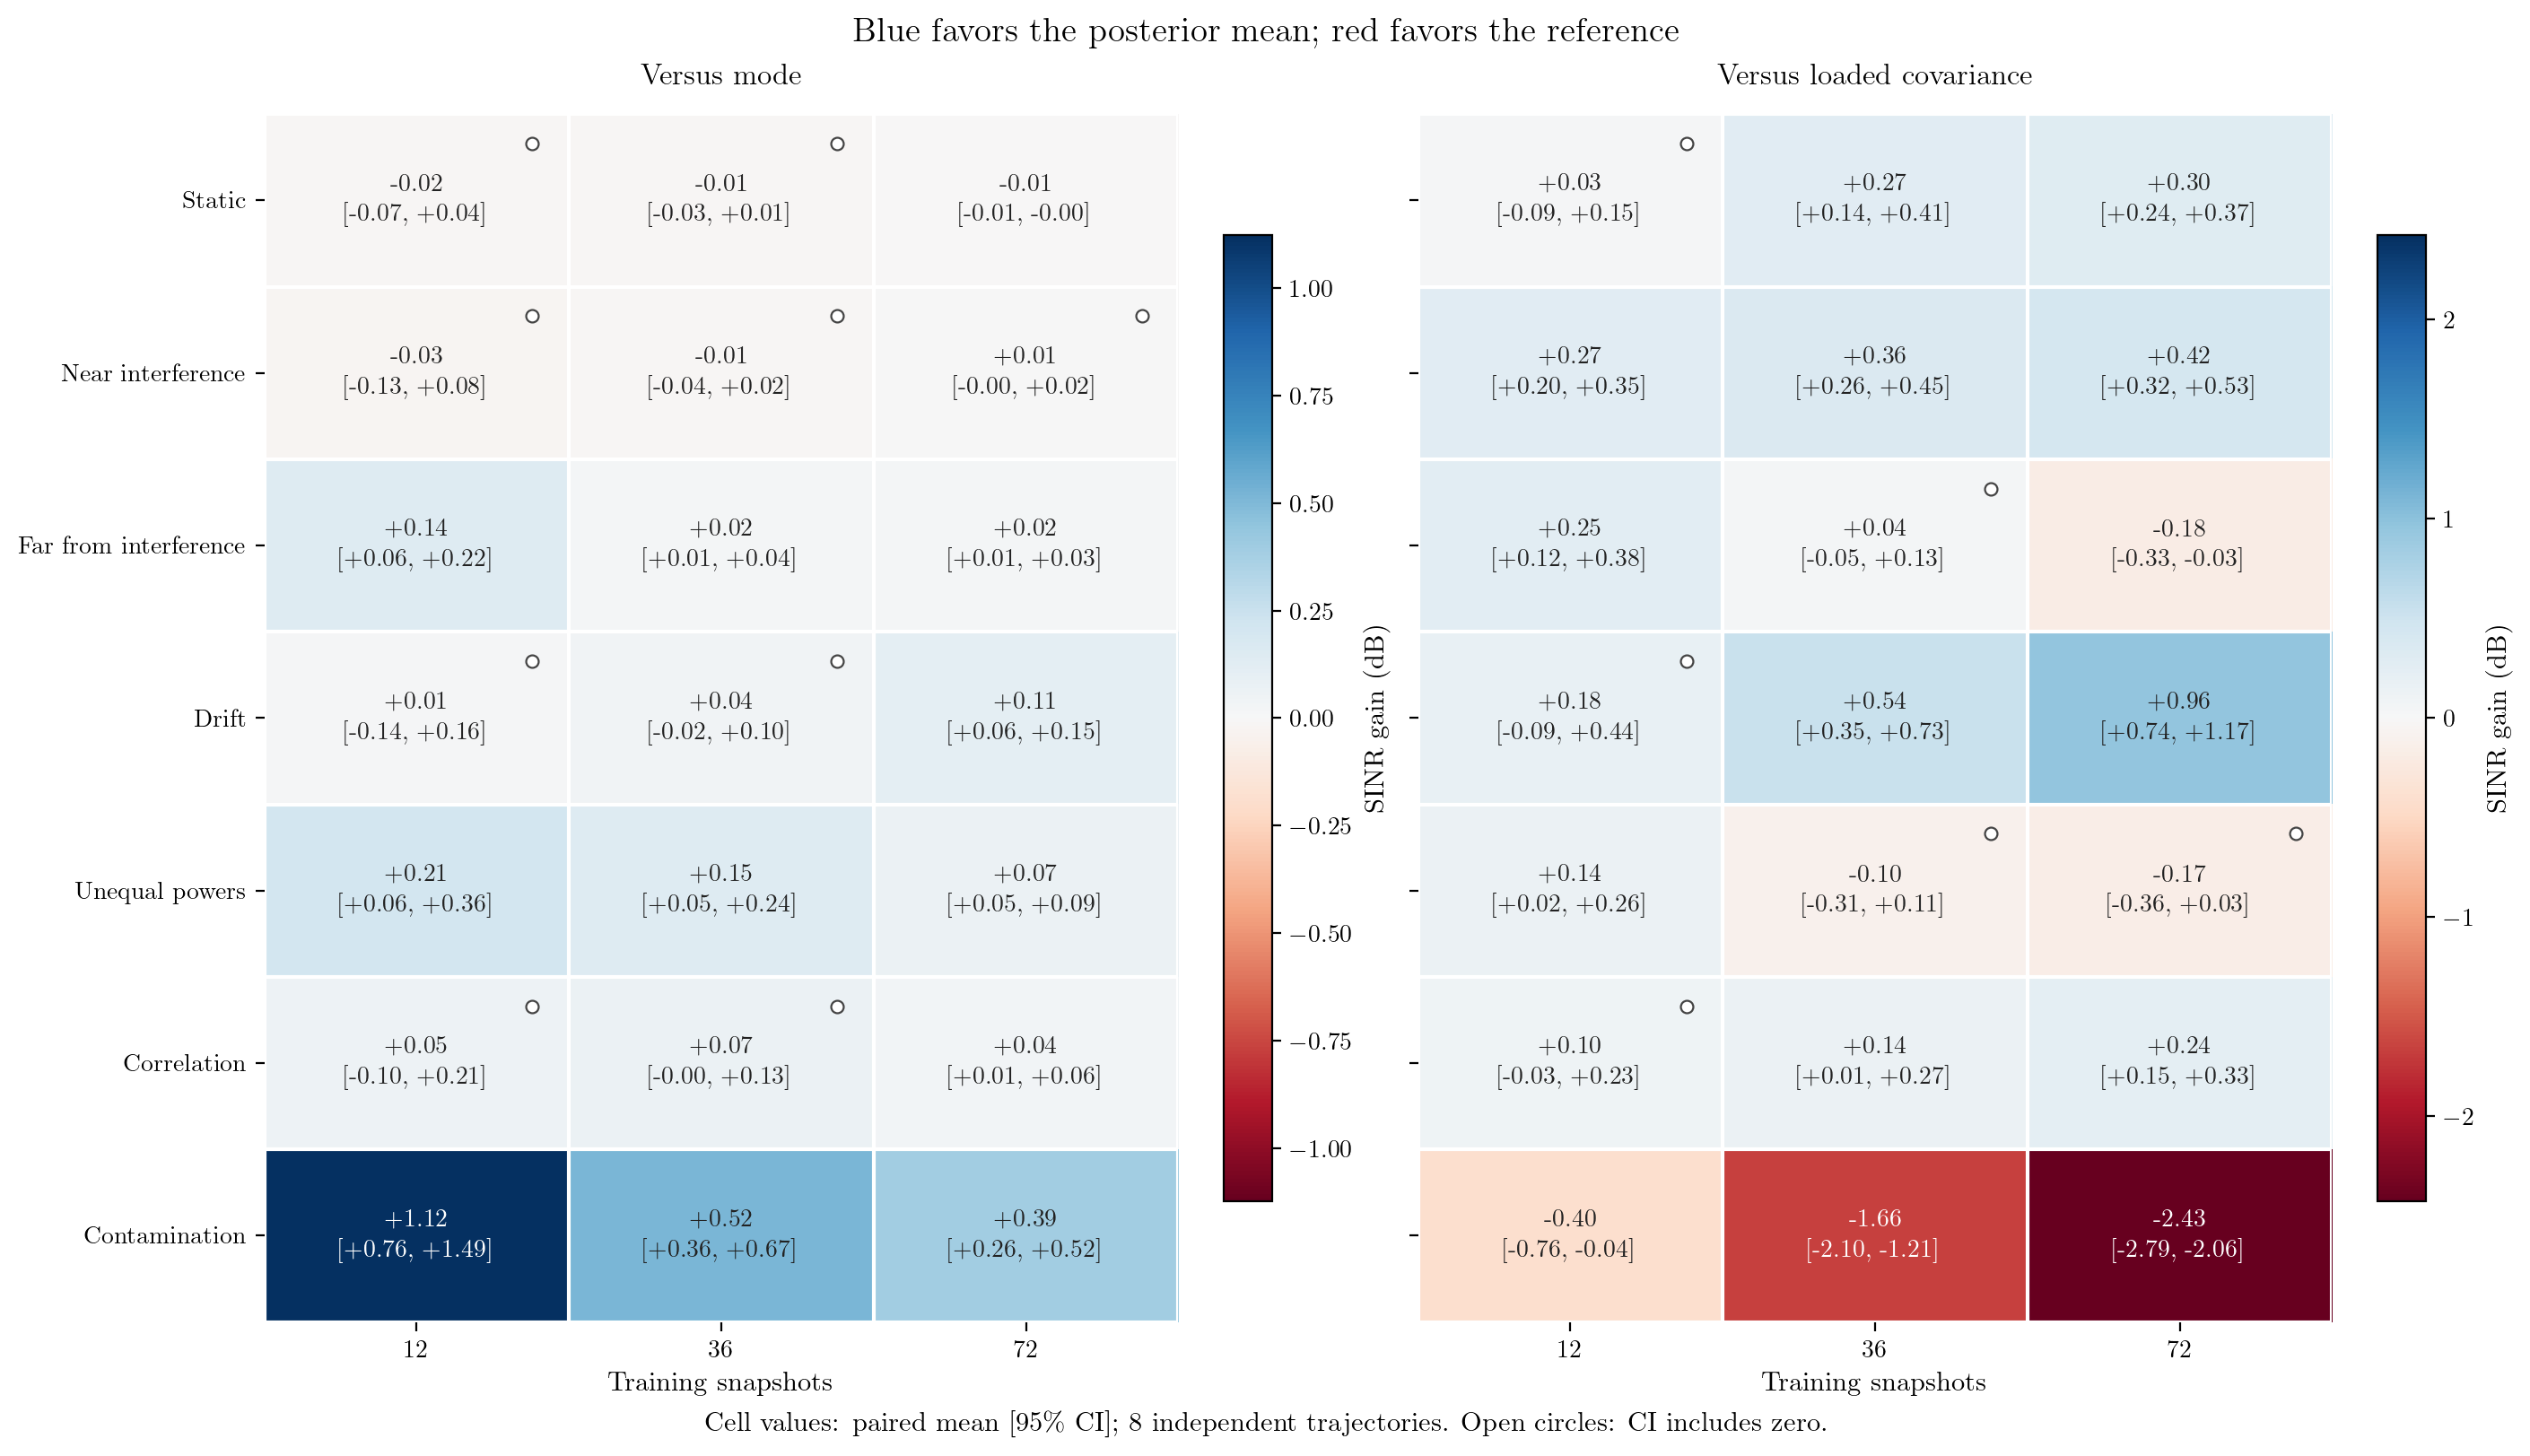

Bingham and matching EW PCA modal distance: 9.8843121241194e-08


In [2]:
show(array_overview(result,path=OUT/'array_results'))
assert m.ew_modal_distance.max()<1e-6
print('Bingham and matching EW PCA modal distance:',m.ew_modal_distance.max())

## Read accuracy together with computation
Horizontal position is measured cumulative work through 72 observations, including the three moment evaluations for the posterior mean. It is not per-observation latency or an intrinsic lower bound for Bayesian methods. The implementation uses a reference MCMC evaluator. Modal updates can run without it, and posterior summaries can be requested less frequently.

The oracle line uses the true covariance and is not an available competitor. The contamination panel is a useful failure case: posterior averaging helps relative to the mode, while loaded covariance is substantially better than both.

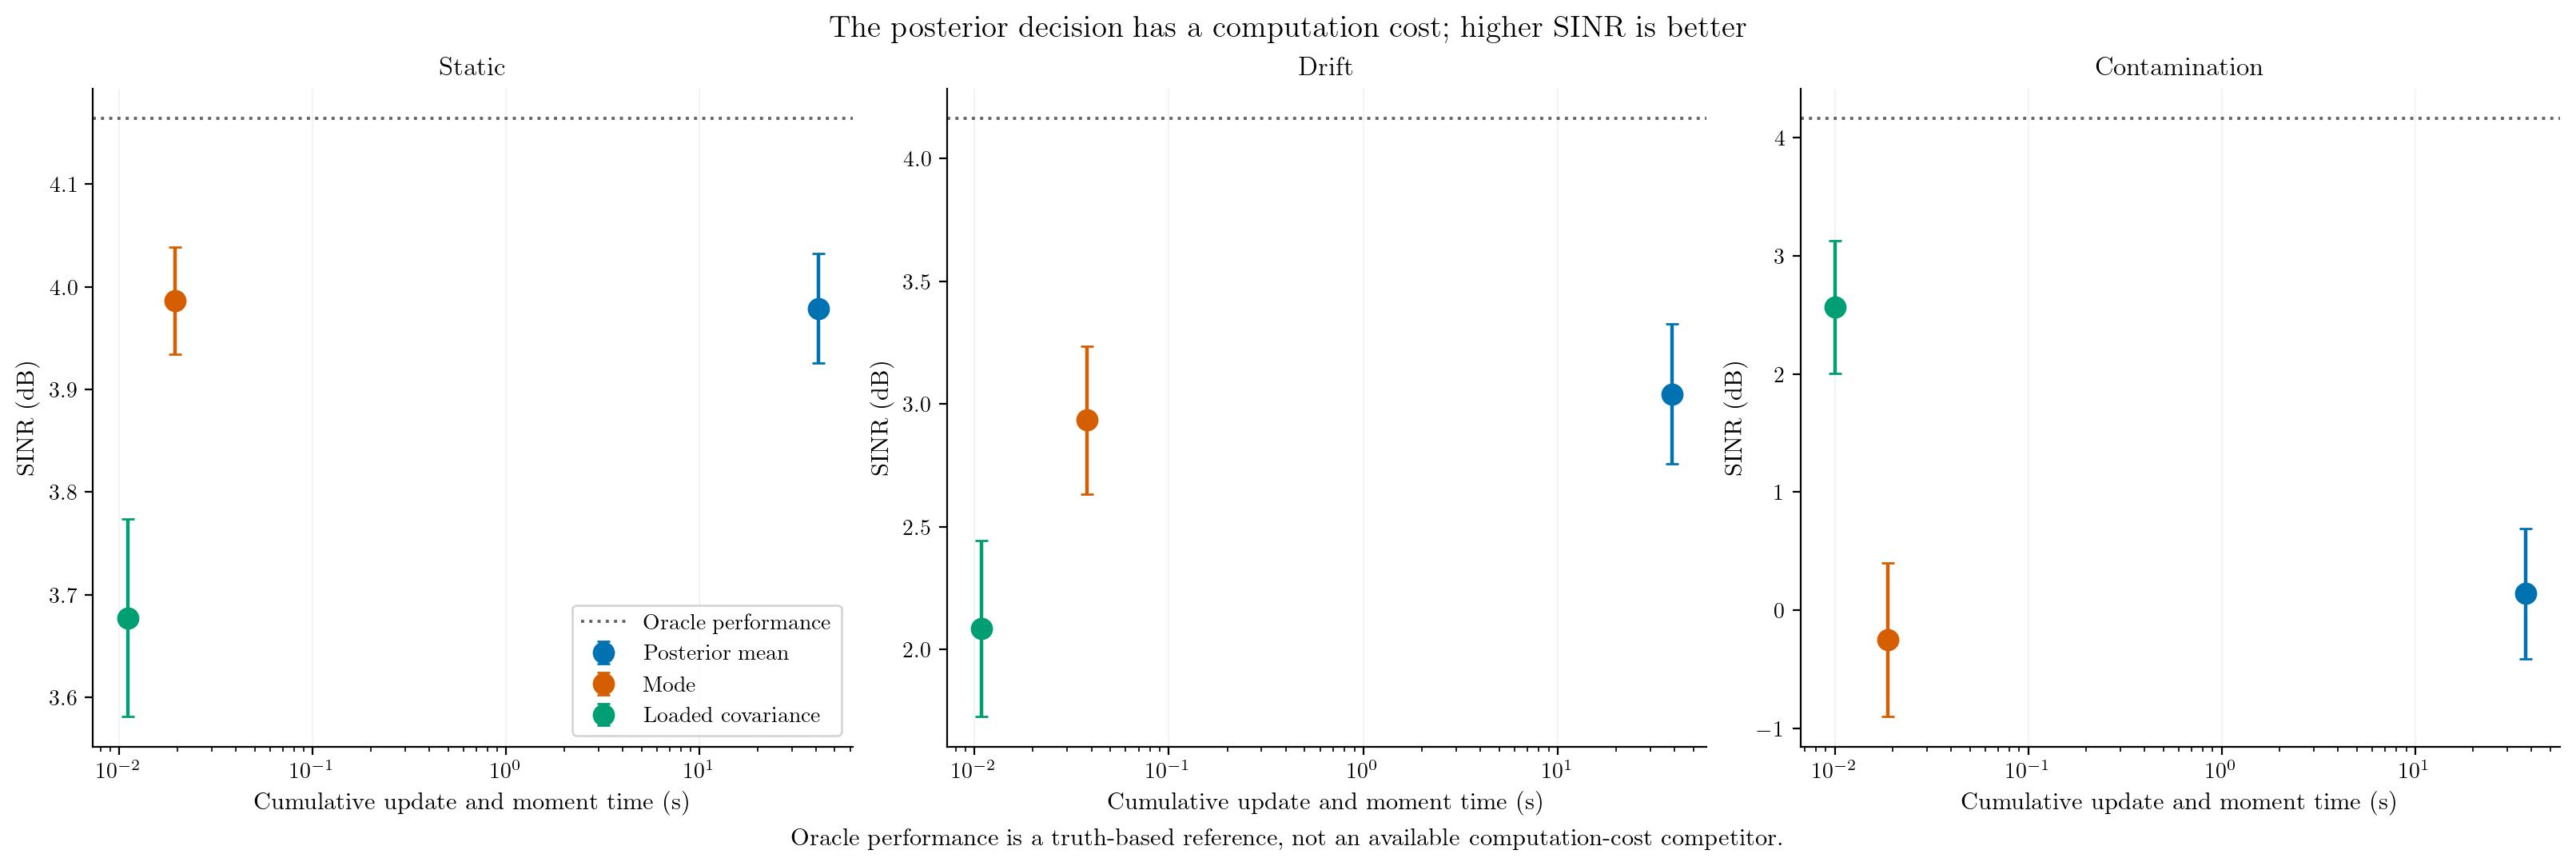

,sinr_db,heldout_power,decision_seconds
method,,,
Loaded covariance,2.638484,0.615589,0.011961
Mode,2.427914,0.649605,0.024717
Oracle,3.665281,0.476112,0.000140
Posterior mean,2.516653,0.632460,46.659964


In [3]:
show(cost_tradeoff(result,path=OUT/'array_tradeoff'))
display(m[m.t==m.t.max()].groupby('method')[['sinr_db','heldout_power','decision_seconds']].mean())

## Regions answer a directional question
The left panel shows empirical terminal coverage with Wilson intervals. “Matched” covariance assumptions do not make the approximate motion model exact. Coverage can fail under forgetting, unmodelled drift, or misspecification.

The right panel compares optimized leakage bounds at equal posterior mass. A ratio below one means the HPD set gives a smaller bound for this beamformer direction; above one means the ball gives the smaller bound. There is no uniformly better region shape. Optimization gaps certify the specified region, not its sampled probability threshold.

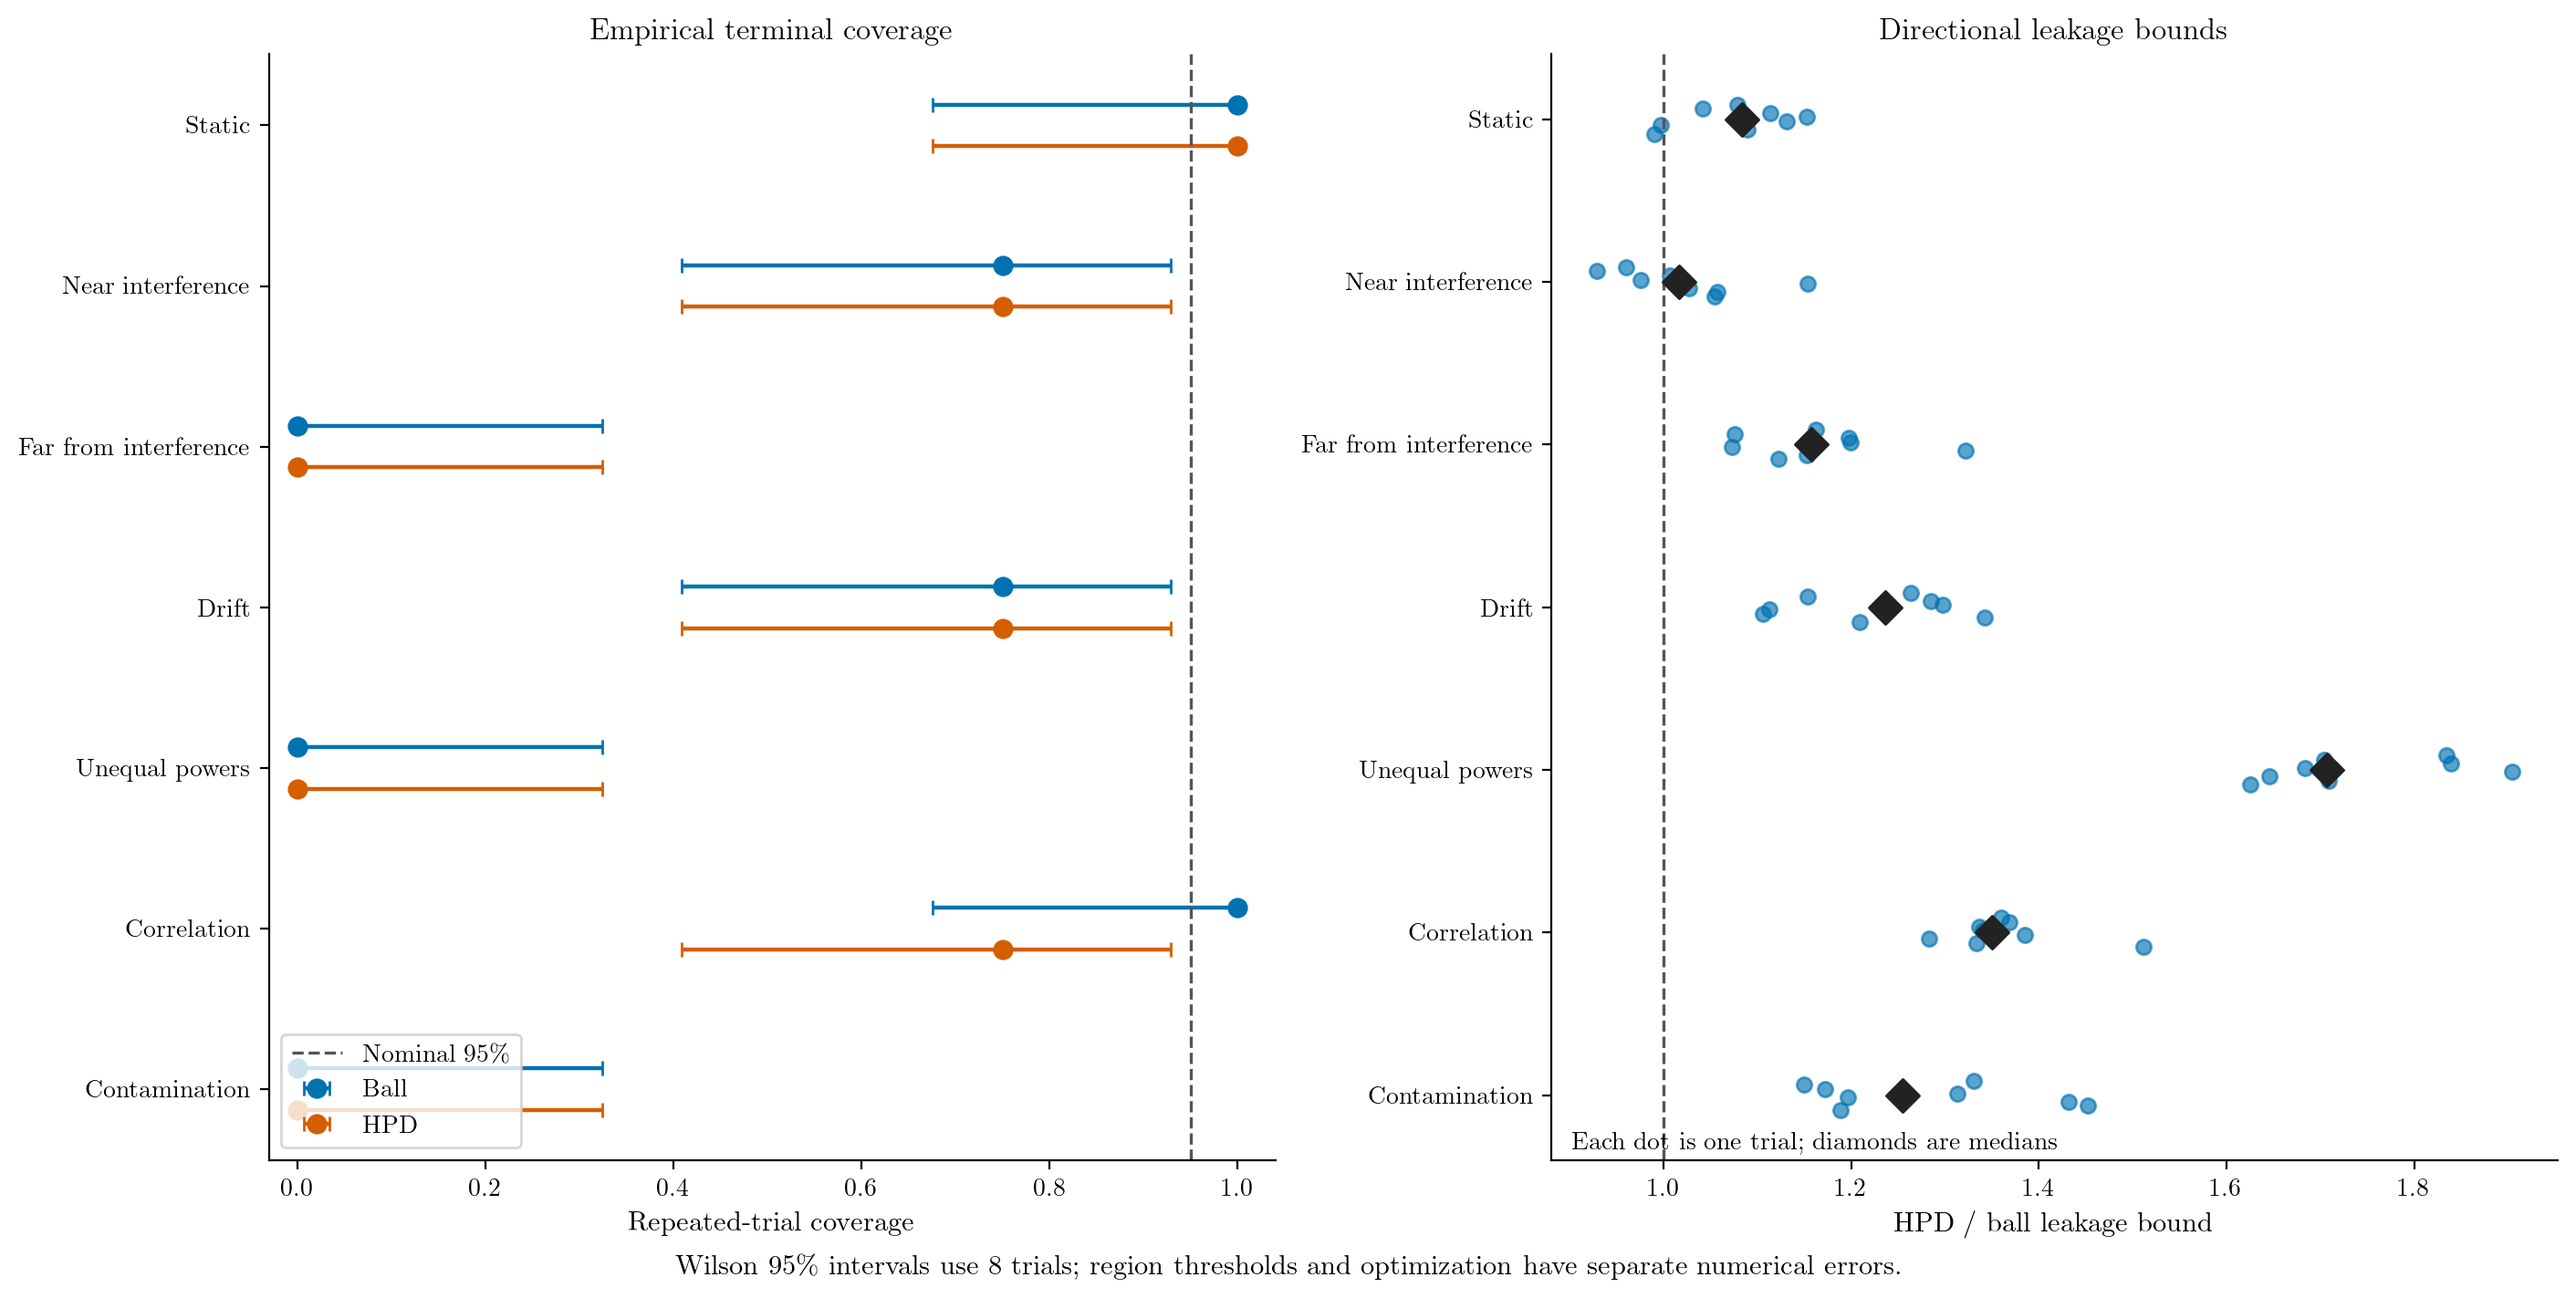

Largest regional optimization gap: 1.003824467549208e-06


In [4]:
show(coverage_regions(result,array=True,path=OUT/'array_regions'))
print('Largest regional optimization gap:',regions.optimization_gap.max())
assert regions.feasible.all() and regions.optimization_gap.max()<1e-5

## A controlled setting where posterior decisions matter
The next experiment isolates low-data decision quality in a stationary **real** rank-one problem in three dimensions. It is a diagnostic counterpart of beamforming, not a claim of superiority in the 16-channel complex study.

All methods receive identical passive observations, the same known noise levels, and independent desired-steering probes. Latent subspaces are sampled from the stated uniform prior. GROUSE, scalar-shrunk PCA, and loaded covariance have independent validation tuning with matched candidate counts. The posterior mean uses deterministic quadrature with separate order-doubling checks.

This stronger control matters: an advantage over a point estimate can come largely from ordinary shrinkage. The scalar-shrunk PCA and loaded-covariance panels show how much remains beyond those cheaper choices. The objective is expected interference power; a lower average power does not imply a win in every realization or for every alternative SINR objective.

Decision study: loading verified cached tables


{'seed': 86021,
 'trials': 400,
 'validation_trials': 160,
 'checkpoints': [1, 2, 4, 8, 16],
 'noise_levels': [1.0, 0.2],
 'tau2': 1.0,
 'n': 3,
 'k': 1,
 'query_directions_per_trial': 8,
 'steps': [0.02, 0.05, 0.08, 0.2, 0.35, 0.5, 1.0, 2.0, 4.0],
 'rhos': [0.0, 0.1, 0.25, 0.4, 0.55, 0.7, 0.85, 0.95, 1.0],
 'loadings': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 1000000.0],
 'candidate_count': 9,
 'coverage_trials_per_regime': 100,
 'coverage_mass': 0.95,
 'calibration_protocol': 'Exact joint Haar prior, stationary state and Gaussian likelihood; predeclared first coverage_trials trajectories at terminal time; not robustness under drift',
 'quadrature_order': 48,
 'reference_order': 96,
 'tolerance': 1e-08,
 'projection_protocol': 'Same passive observations; fresh independent unit queries supplied to every method at decision time',
 'reconstruction_protocol': 'Same current observation; known noise; Prior mean uses isotropic LMMSE, other methods use conditional Wiener shrinkage',
 'bea

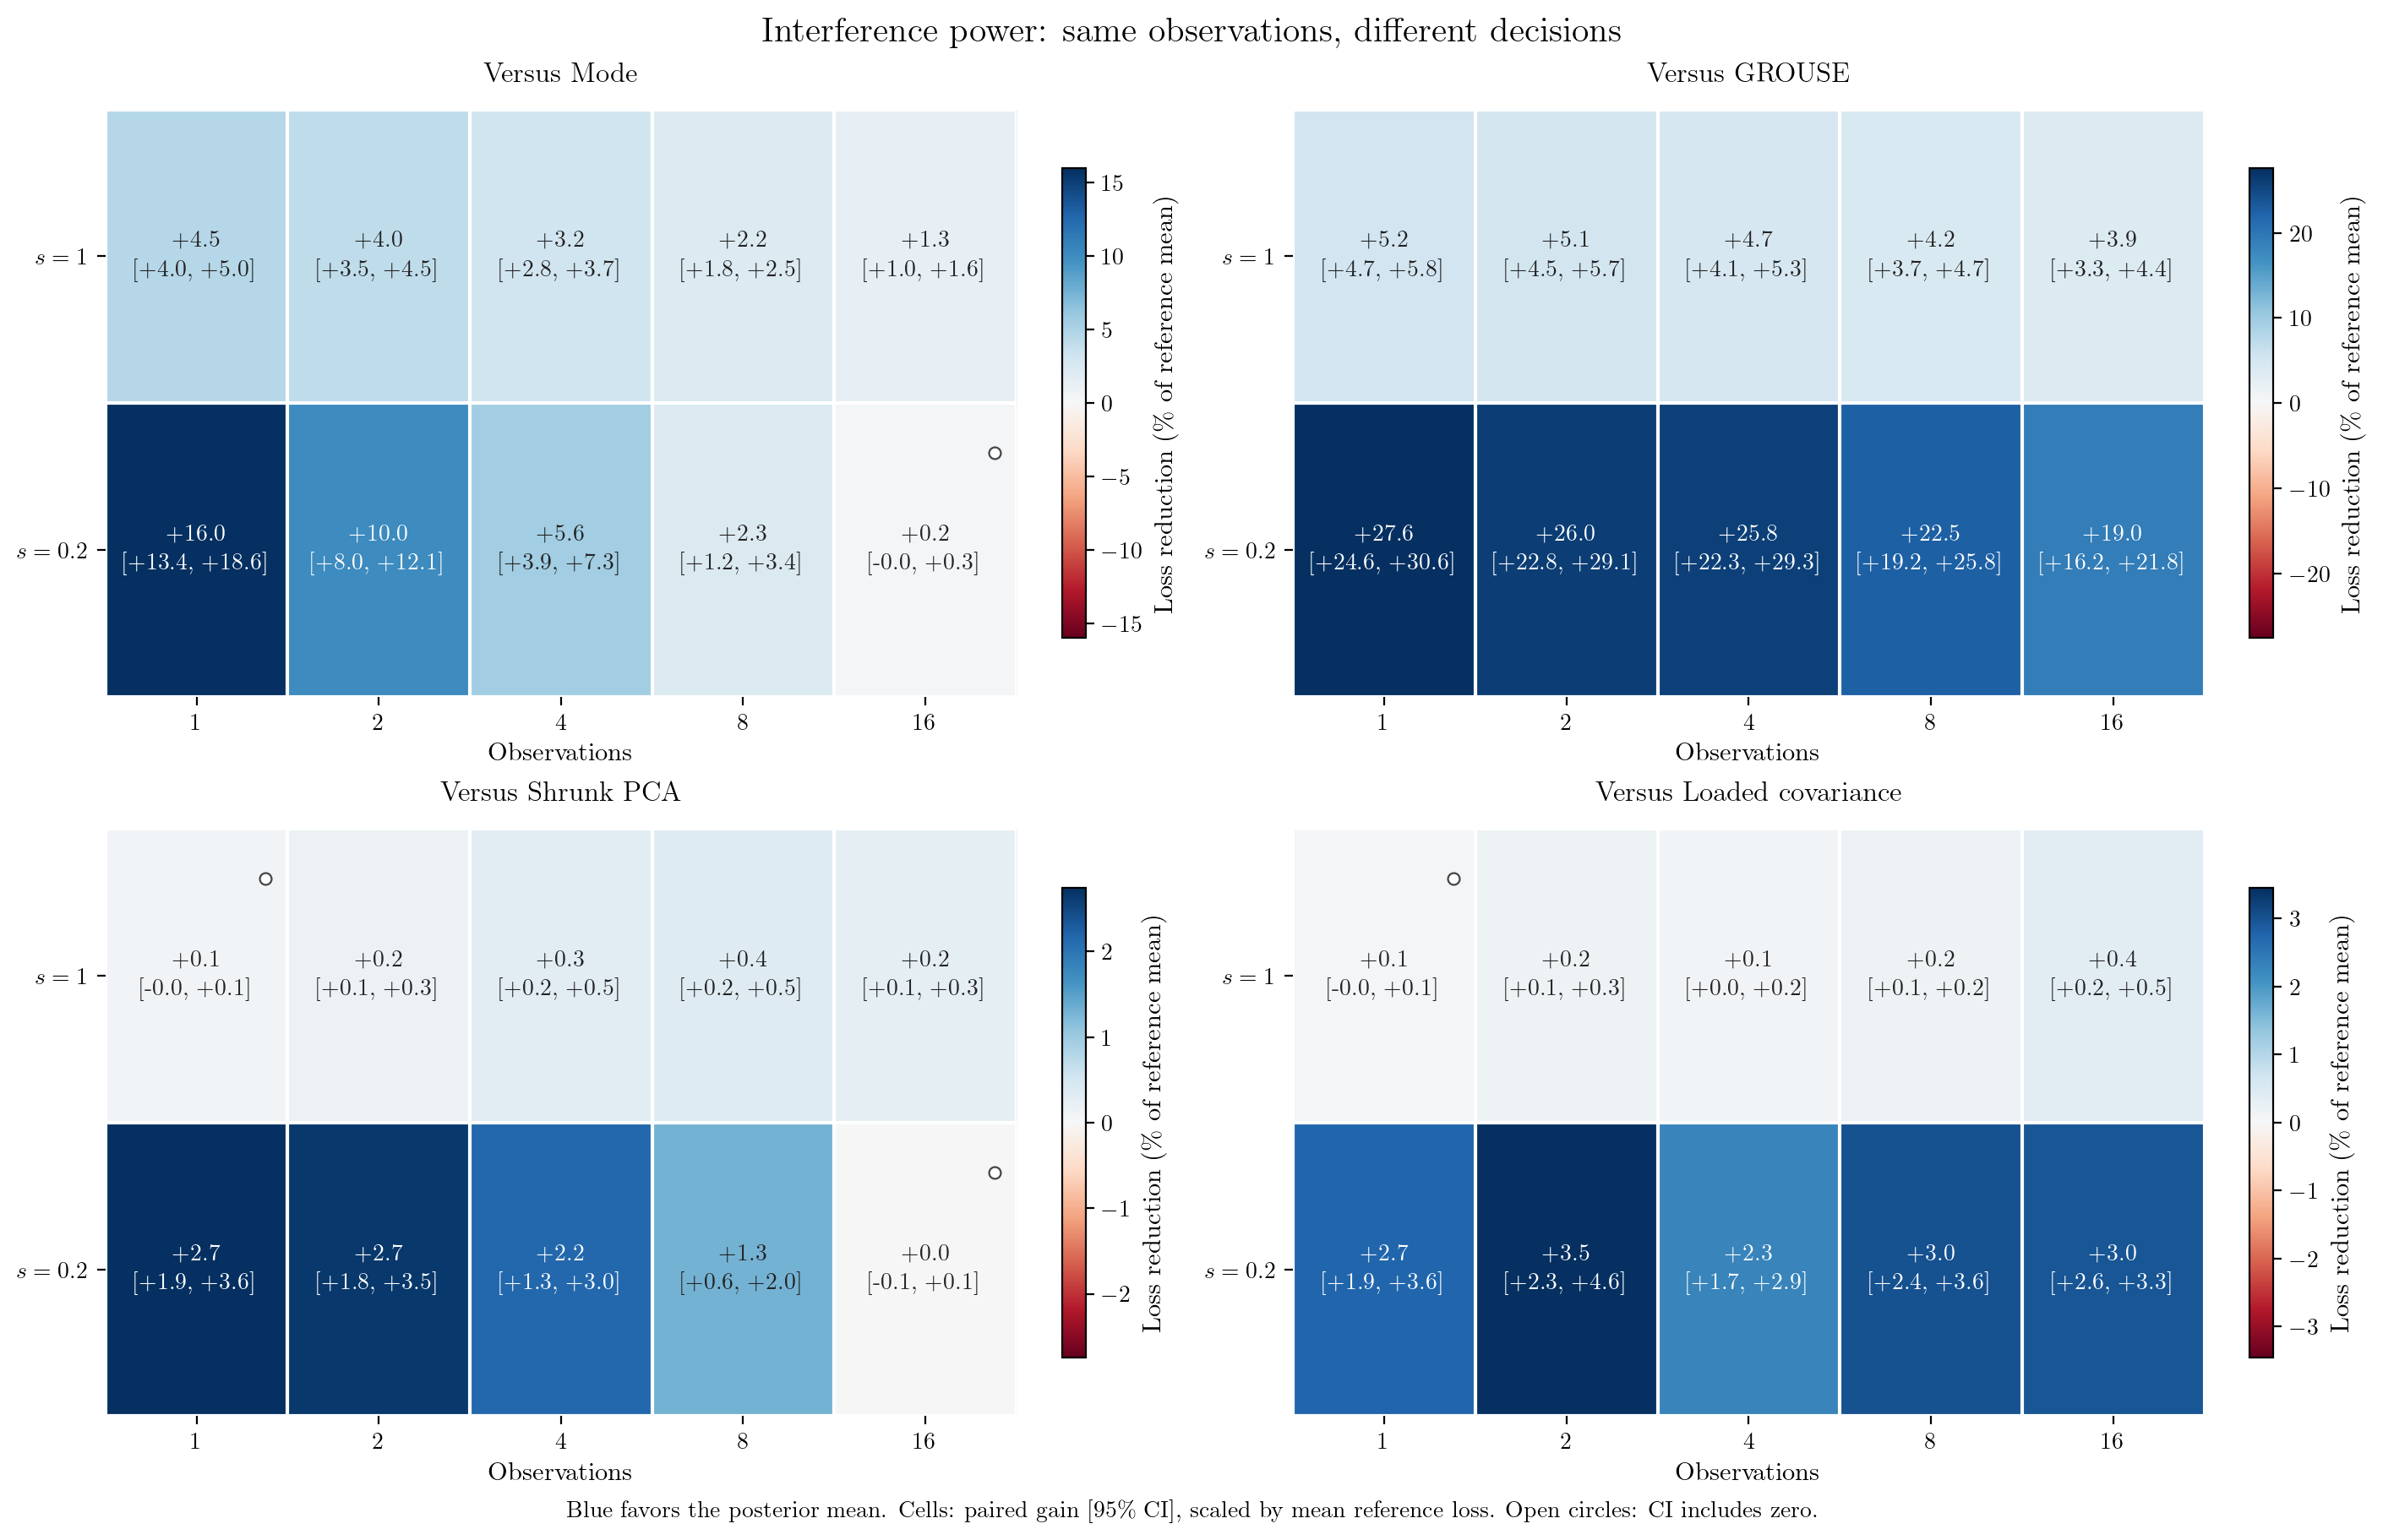

,regime,t,reference,baseline_loss,posterior_loss,reduction_percent,gain_low,gain_high
12,0,1,EW PCA,1.387351,1.324760,4.511504,0.055160,0.070021
13,0,1,GROUSE,1.398157,1.324760,5.249546,0.065494,0.081300
14,0,1,Loaded covariance,1.325719,1.324760,0.072277,-0.000015,0.001931
15,0,1,Mode,1.387351,1.324760,4.511504,0.055160,0.070021
16,0,1,Oracle,1.241246,1.324760,-6.728296,-0.086164,-0.080865
17,0,1,Prior mean,1.326939,1.324760,0.164216,0.000550,0.003809
18,0,1,Shrunk PCA,1.325703,1.324760,0.071099,-0.000083,0.001968
88,0,16,EW PCA,1.312581,1.295394,1.309353,0.013616,0.020756
89,0,16,GROUSE,1.347681,1.295394,3.879754,0.044986,0.059587
90,0,16,Loaded covariance,1.300326,1.295394,0.379253,0.003222,0.006641


In [5]:
# This runs only if the controlled-study source or parameters changed.
subprocess.run([sys.executable,str(ROOT/'scripts/run_decision_study.py')],cwd=ROOT,check=True)
study=load_study(ROOT)
display(study['config'])
assert study['accuracy'].reference_difference.max()<=study['config']['tolerance']

show(gain_maps(study,task='Beamforming',path=OUT/'array_low_data'))
display(study['paired'][(study['paired'].task=='Beamforming')&study['paired'].t.isin([1,16])][['regime','t','reference','baseline_loss','posterior_loss','reduction_percent','gain_low','gain_high']])

## Numerical accuracy is part of the result
Orange outlines identify where the original budget missed the ESS threshold. All original failures remain visible. The separate longer-chain follow-up reconstructs the same posterior targets with independent random streams; it does not replace inconvenient original observations.

The historical follow-up is reused only after checking its raw-table checksum, original numerical dependencies, and core certificate. Display-only changes are excluded from that numerical dependency comparison. Diagnostics are evidence about the stated budgets, not a convergence proof.

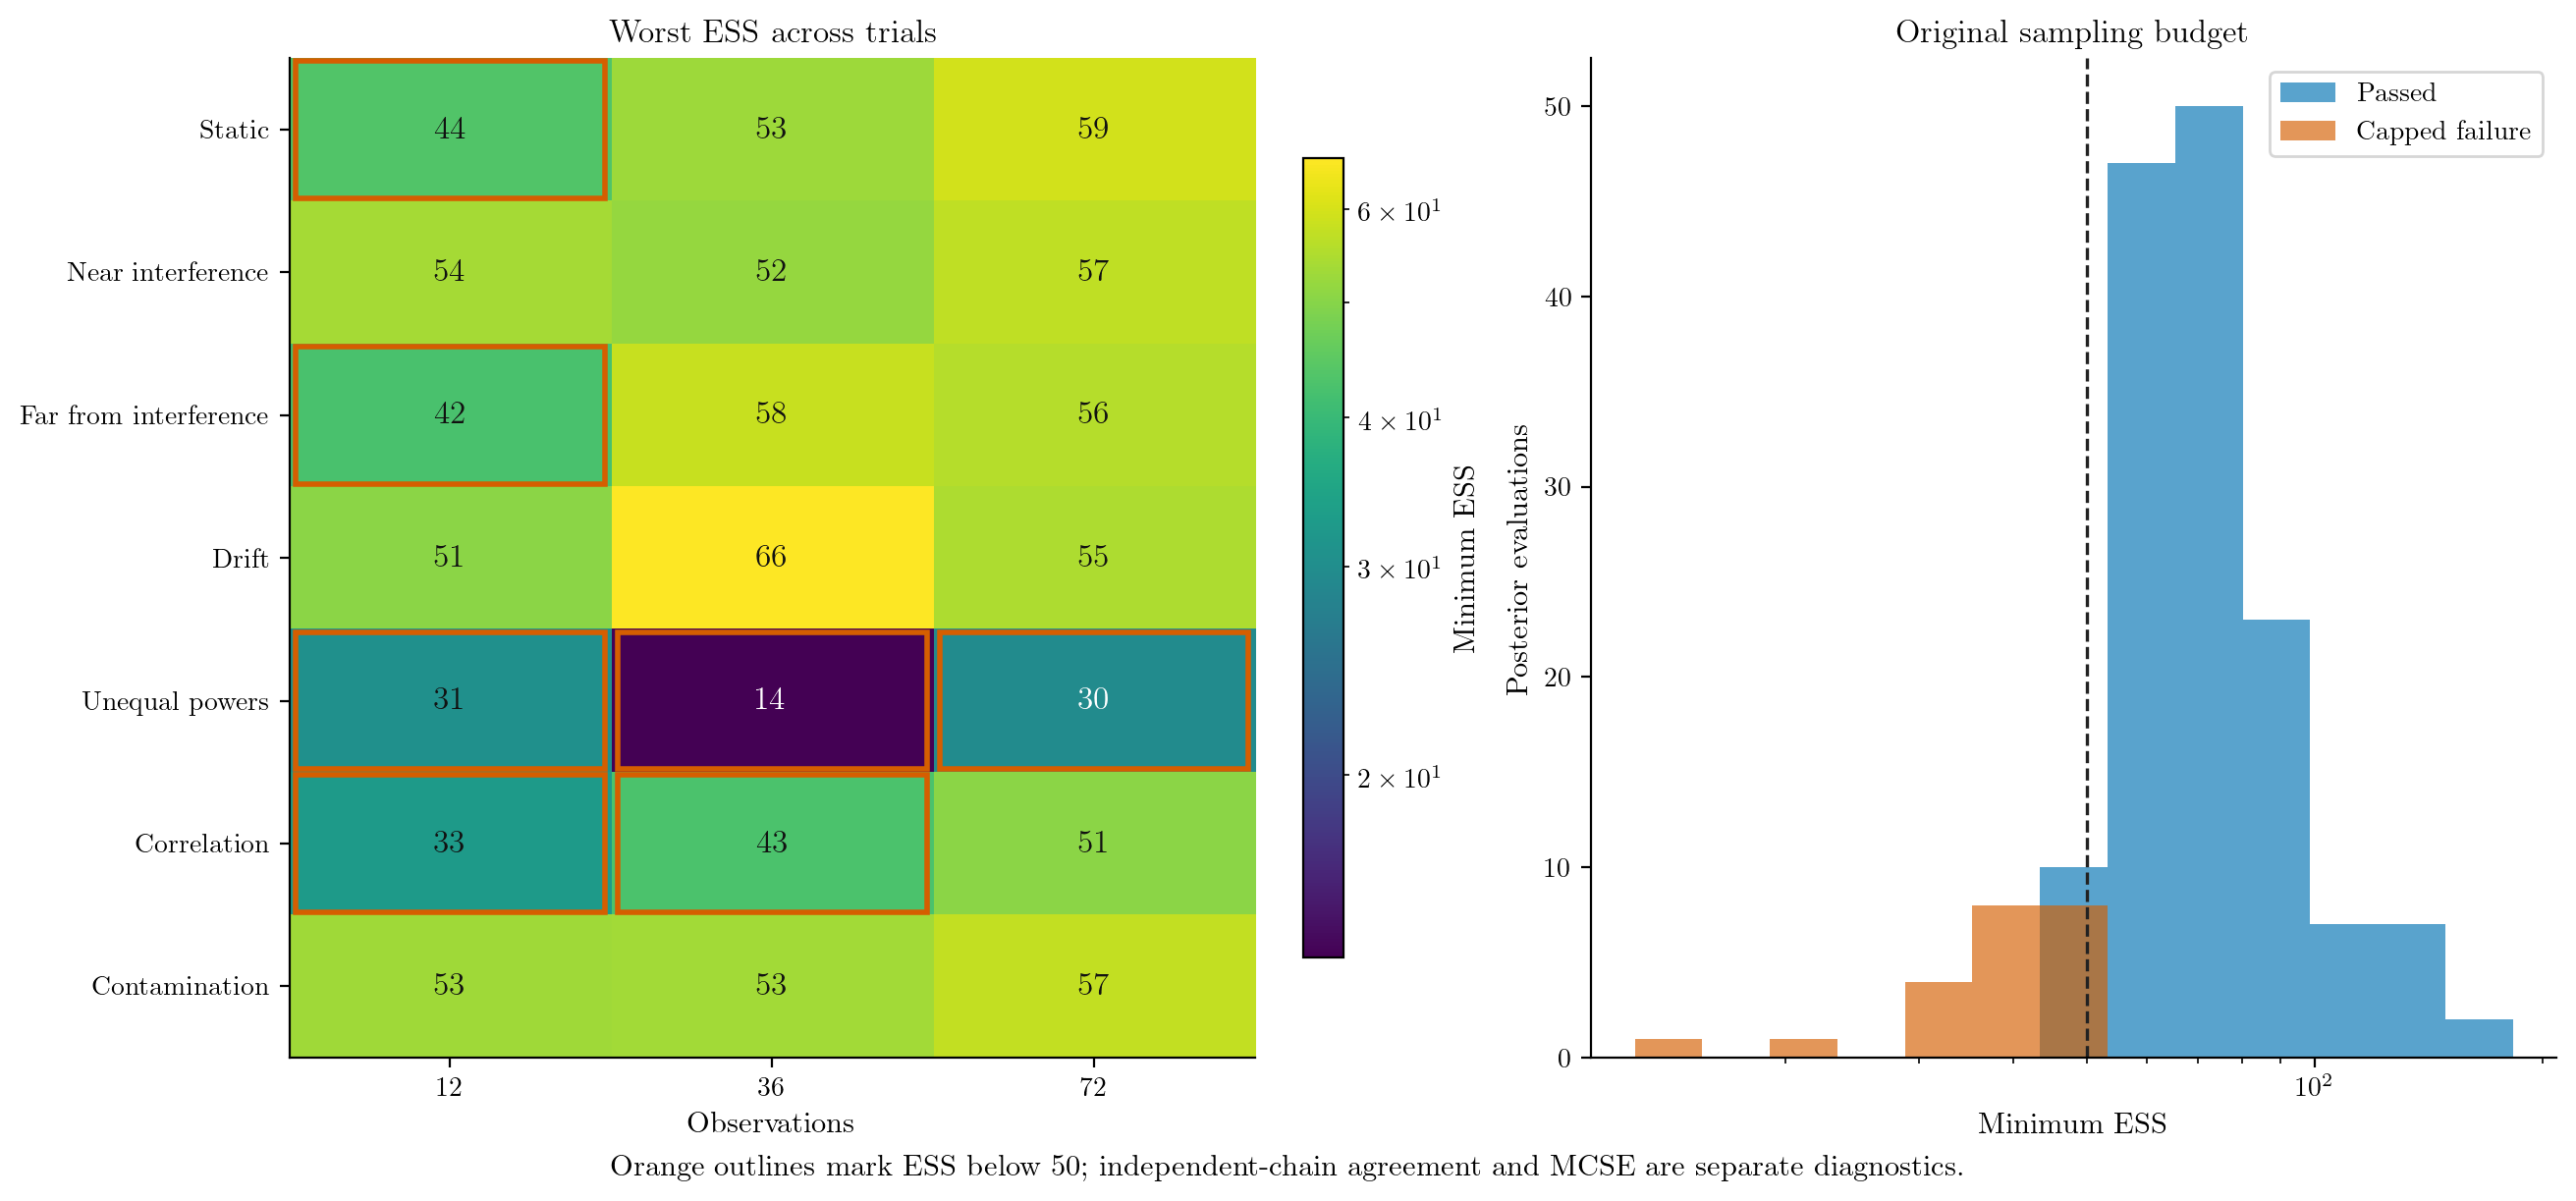

,scenario,repeat,t,old_min_ess,new_min_ess,new_max_rhat,output_power_relative_change
0,Correlation,0,12,32.611747,117.483201,1.012387,0.001562
1,Correlation,1,12,46.265820,67.570630,1.012472,0.000034
2,Correlation,2,36,42.612573,160.451149,1.013057,-0.000661
3,Correlation,3,12,37.644181,95.050944,1.013700,0.002121
4,Correlation,3,36,44.882350,93.637003,1.012176,-0.003657
5,Correlation,6,12,44.497128,68.204242,1.014618,-0.001567
6,Correlation,7,12,39.257454,76.692327,1.020104,-0.000846
7,Far from interference,2,12,42.317950,98.272237,1.006743,-0.002168
8,Static,1,12,43.520185,115.400337,1.007428,-0.001281
9,Unequal powers,0,12,32.555983,77.287428,1.015882,0.000607


Maximum population-power sensitivity: 0.0036569343065248


In [6]:
show(sampler_overview(result,array=True,path=OUT/'array_accuracy'))
a_meta=json.loads((OUT/'case1_accuracy.json').read_text())
assert a_meta['core_hash']==require_gate(ROOT)['core_hash']
assert hashlib.sha256((OUT/'case1_accuracy.csv').read_bytes()).hexdigest()==a_meta['result_sha256']
for name,digest in a_meta['source']['files'].items():
    if name=='lib/plotting.py':continue  # only its presentation settings changed
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest()==digest,name
for name,digest in a_meta['input_sha256'].items():
    if name=='results/validation.json':continue  # the core hash above is the invariant
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest()==digest,name
accuracy=pd.read_csv(OUT/'case1_accuracy.csv')
assert accuracy.new_sampling_ok.all()
display(accuracy[['scenario','repeat','t','old_min_ess','new_min_ess','new_max_rhat','output_power_relative_change']])
print('Maximum population-power sensitivity:',accuracy.output_power_relative_change.abs().max())
